# Unit 5–6 Assignment: Letter Recognition Using Classification Trees

## 1. Setup and Data Import

This analysis uses a decision tree classification model to predict uppercase
English letters from 16 numerical attributes derived from character images.
The required Python libraries are imported below, and the letter recognition
dataset is loaded for analysis.

In [1]:
# Data management
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Decision tree modeling
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Cross-validation and model tuning
from sklearn.model_selection import KFold, GridSearchCV

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Reproducibility
RANDOM_STATE = 42


In [2]:
# Load the letter recognition dataset
letters = pd.read_csv("letter.csv")

# Preview the dataset
letters.head()

,xbox,ybox,width,high,onpix,xbar,ybar,x2bar,y2bar,xybar,x2ybr,xy2br,xege,xegvy,yege,yegvx,class
0,2,4,4,3,2,7,8,2,9,11,7,7,1,8,5,6,Z
1,4,7,5,5,5,5,9,6,4,8,7,9,2,9,7,10,P
2,7,10,8,7,4,8,8,5,10,11,2,8,2,5,5,10,S
3,4,9,5,7,4,7,7,13,1,7,6,8,3,8,0,8,H
4,6,7,8,5,4,7,6,3,7,10,7,9,3,8,3,7,H


## 2. Data Structure and Quality Checks

The structure and quality of the dataset are examined before exploratory
analysis and model fitting. This includes reviewing the dataset dimensions,
variable types, summary statistics, missing values, duplicate observations,
and the number of target classes.


In [3]:
# Display dataset dimensions
print("Dataset shape:", letters.shape)

# Display column names
print("\nColumn names:")
print(letters.columns.tolist())

Dataset shape: (20000, 17)

Column names:
['xbox', 'ybox', 'width', 'high', 'onpix', 'xbar', 'ybar', 'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'xege', 'xegvy', 'yege', 'yegvx', 'class']


In [4]:
# Review variable types and non-null counts
letters.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   xbox    20000 non-null  int64
 1   ybox    20000 non-null  int64
 2   width   20000 non-null  int64
 3   high    20000 non-null  int64
 4   onpix   20000 non-null  int64
 5   xbar    20000 non-null  int64
 6   ybar    20000 non-null  int64
 7   x2bar   20000 non-null  int64
 8   y2bar   20000 non-null  int64
 9   xybar   20000 non-null  int64
 10  x2ybr   20000 non-null  int64
 11  xy2br   20000 non-null  int64
 12  xege    20000 non-null  int64
 13  xegvy   20000 non-null  int64
 14  yege    20000 non-null  int64
 15  yegvx   20000 non-null  int64
 16  class   20000 non-null  str  
dtypes: int64(16), str(1)
memory usage: 2.6 MB


In [5]:
# Summary statistics for the numerical predictors
letters.describe().T

,count,mean,std,min,25%,50%,75%,max
xbox,20000.0,4.02355,1.913212,0.0,3.0,4.0,5.0,15.0
ybox,20000.0,7.03550,3.304555,0.0,5.0,7.0,9.0,15.0
width,20000.0,5.12185,2.014573,0.0,4.0,5.0,6.0,15.0
high,20000.0,5.37245,2.261390,0.0,4.0,6.0,7.0,15.0
onpix,20000.0,3.50585,2.190458,0.0,2.0,3.0,5.0,15.0
xbar,20000.0,6.89760,2.026035,0.0,6.0,7.0,8.0,15.0
ybar,20000.0,7.50045,2.325354,0.0,6.0,7.0,9.0,15.0
x2bar,20000.0,4.62860,2.699968,0.0,3.0,4.0,6.0,15.0
y2bar,20000.0,5.17865,2.380823,0.0,4.0,5.0,7.0,15.0
xybar,20000.0,8.28205,2.488475,0.0,7.0,8.0,10.0,15.0


In [6]:
# Check for missing values
letters.isnull().sum()

xbox     0
ybox     0
width    0
high     0
onpix    0
xbar     0
ybar     0
x2bar    0
y2bar    0
xybar    0
x2ybr    0
xy2br    0
xege     0
xegvy    0
yege     0
yegvx    0
class    0
dtype: int64

In [7]:
# Check for exact duplicate rows
duplicate_count = letters.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 1332


In [8]:
# Confirm the number of target classes
print("Number of letter classes:", letters["class"].nunique())

# Display observations per class
class_counts = letters["class"].value_counts().sort_index()
class_counts

Number of letter classes: 26


class
A    789
B    766
C    736
D    805
E    768
F    775
G    773
H    734
I    755
J    747
K    739
L    761
M    792
N    783
O    753
P    803
Q    783
R    758
S    748
T    796
U    813
V    764
W    752
X    787
Y    786
Z    734
Name: count, dtype: int64

In [9]:
# Summarize key dataset checks
print(f"Observations: {letters.shape[0]}")
print(f"Variables: {letters.shape[1]}")
print(f"Numerical predictors: {letters.select_dtypes(include='number').shape[1]}")
print(f"Target classes: {letters['class'].nunique()}")
print(f"Missing values: {letters.isnull().sum().sum()}")
print(f"Exact duplicate rows: {letters.duplicated().sum()}")

Observations: 20000
Variables: 17
Numerical predictors: 16
Target classes: 26
Missing values: 0
Exact duplicate rows: 1332


In [10]:
# Check whether identical predictor values ever map to different letter classes
feature_columns = letters.columns.drop("class")

conflicting_classes = (
    letters.groupby(list(feature_columns))["class"]
    .nunique()
    .gt(1)
    .sum()
)

print("Feature vectors assigned to multiple classes:", conflicting_classes)

Feature vectors assigned to multiple classes: 0


### Data Quality Summary

The dataset contains 20,000 observations, 16 numerical predictors, and 26
letter classes. No missing values were identified. Although 1,332 exact
duplicate rows were present, these observations were retained because the
source images were transformed into a limited set of integer-valued numerical
features. Identical predictor combinations were also checked for conflicting
class labels before modeling.

## 3. Exploratory Data Analysis

Exploratory analysis was performed to examine the distribution of the target
classes and selected numerical predictors. Representative variables were chosen
from different types of image characteristics, including bounding-box geometry,
pixel density, pixel dispersion, and edge structure.

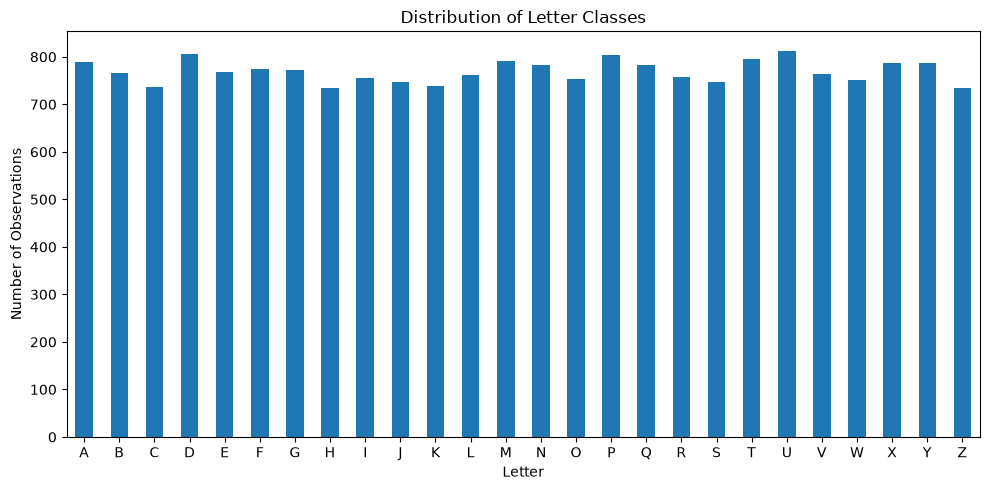

In [11]:
# Plot the distribution of letter classes
class_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Distribution of Letter Classes")
plt.xlabel("Letter")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Summarize class balance
print("Smallest class count:", class_counts.min())
print("Largest class count:", class_counts.max())
print("Mean class count:", round(class_counts.mean(), 2))

Smallest class count: 734
Largest class count: 813
Mean class count: 769.23


In [13]:
# Summary statistics for selected predictors
selected_features = ["width", "onpix", "x2bar", "xege"]

letters[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
width,20000.0,5.12185,2.014573,0.0,4.0,5.0,6.0,15.0
onpix,20000.0,3.50585,2.190458,0.0,2.0,3.0,5.0,15.0
x2bar,20000.0,4.62860,2.699968,0.0,3.0,4.0,6.0,15.0
xege,20000.0,3.04610,2.332541,0.0,1.0,3.0,4.0,15.0


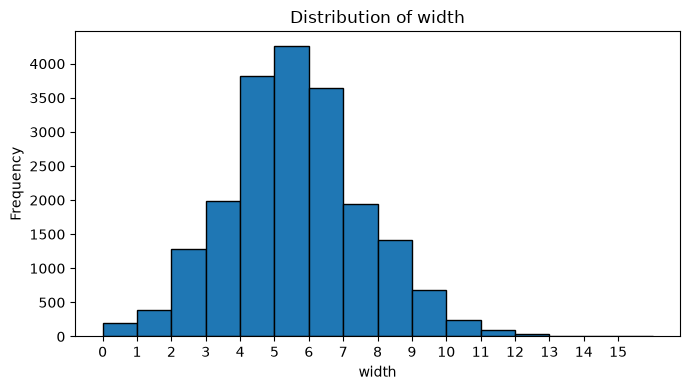

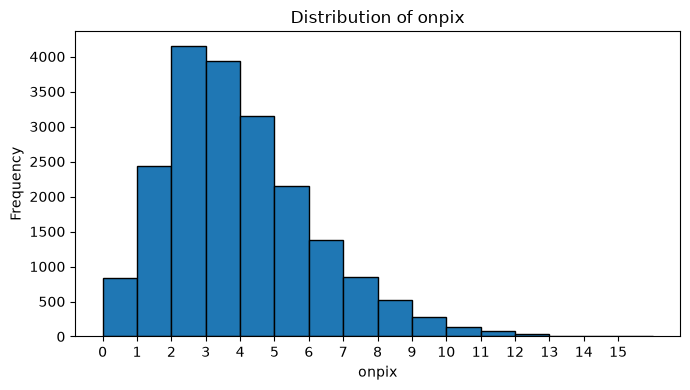

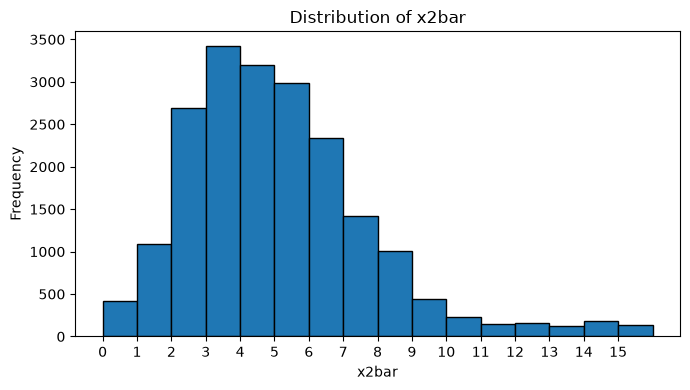

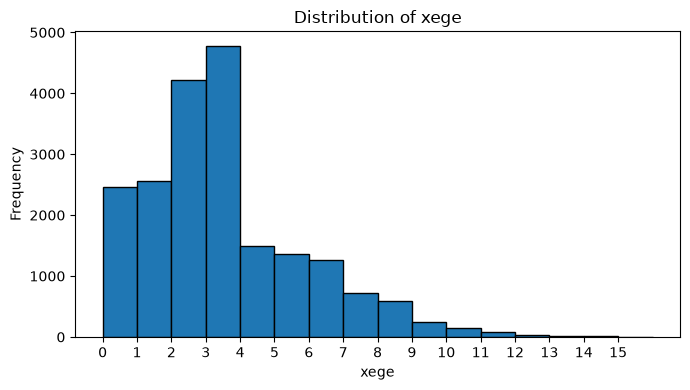

In [14]:
# Plot distributions of selected numerical predictors
for feature in selected_features:
    plt.figure(figsize=(7, 4))
    plt.hist(letters[feature], bins=range(17), edgecolor="black")
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.xticks(range(16))
    plt.tight_layout()
    plt.show()

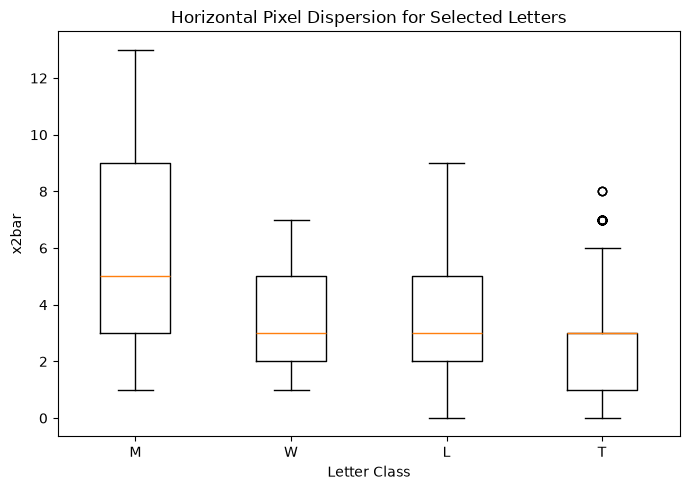

In [15]:
# Compare horizontal pixel dispersion for selected letter classes
comparison_letters = ["M", "W", "L", "T"]

x2bar_groups = [
    letters.loc[letters["class"] == letter, "x2bar"]
    for letter in comparison_letters
]

plt.figure(figsize=(7, 5))
plt.boxplot(x2bar_groups)
plt.xticks(
    range(1, len(comparison_letters) + 1),
    comparison_letters
)

plt.title("Horizontal Pixel Dispersion for Selected Letters")
plt.xlabel("Letter Class")
plt.ylabel("x2bar")
plt.tight_layout()
plt.show()

In [16]:
# Summarize x2bar by selected letter class
letters.loc[
    letters["class"].isin(comparison_letters)
].groupby("class")["x2bar"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
class,,,,
L,761,3.450723,3.0,1.954213
M,792,6.041667,5.0,3.406624
T,796,2.556533,3.0,1.663691
W,752,3.488032,3.0,1.351575


### Exploratory Analysis Summary

The 26 target classes were relatively balanced across the dataset, with no
single letter substantially overrepresented. The selected numerical predictors
displayed different distributional patterns across their 0–15 integer scales.
Width was concentrated near the middle of its range, while onpix, x2bar, and
xege showed varying degrees of right skew.

A focused comparison of horizontal pixel dispersion (x2bar) among the letters
M, W, L, and T showed that M had the highest mean value (6.04) and median
value (5.0). W and L had similar mean values of 3.49 and 3.45, respectively,
while T had the lowest mean value at 2.56. These results indicate that horizontal
pixel dispersion varies across letter classes and may provide useful information
for classification.


## 4. Preprocessing and Data Split

The exploratory and quality checks identified no missing values, and all 16
predictor variables were already stored as numerical values. Therefore, no
imputation or categorical encoding of the predictors was required.

Following the original dataset design, the first 16,000 observations were used
for model training and the remaining 4,000 observations were reserved as an
independent test set.

In [17]:
# Separate predictors and target variable
X = letters.drop(columns="class")
y = letters["class"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (20000, 16)
Target shape: (20000,)


In [18]:
# Use the original 16,000 / 4,000 training-test split
X_train = X.iloc[:16000].copy()
X_test = X.iloc[16000:].copy()

y_train = y.iloc[:16000].copy()
y_test = y.iloc[16000:].copy()

print("Training predictors:", X_train.shape)
print("Training target:", y_train.shape)
print("Test predictors:", X_test.shape)
print("Test target:", y_test.shape)

Training predictors: (16000, 16)
Training target: (16000,)
Test predictors: (4000, 16)
Test target: (4000,)


In [19]:
# Verify that all 26 letter classes are represented in both sets
print("Training classes:", y_train.nunique())
print("Test classes:", y_test.nunique())

print("\nTraining class range:")
print(sorted(y_train.unique()))

print("\nTest class range:")
print(sorted(y_test.unique()))

Training classes: 26
Test classes: 26

Training class range:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

Test class range:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [20]:
# Compare class counts in the training and test sets
split_class_counts = pd.DataFrame({
    "Training": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index()
})

split_class_counts

,Training,Test
class,,
A,633,156
B,606,160
C,589,147
D,638,167
E,616,152
F,619,156
G,586,187
H,571,163
I,608,147


In [21]:
# Check for predictor vectors that appear in both training and test sets
train_vectors = set(map(tuple, X_train.to_numpy()))
test_vectors = set(map(tuple, X_test.to_numpy()))

shared_vectors = train_vectors.intersection(test_vectors)

print("Unique predictor vectors shared across training and test sets:",
      len(shared_vectors))

Unique predictor vectors shared across training and test sets: 336


In [22]:
# Count test observations whose predictor vector also appears in training
train_vectors = pd.MultiIndex.from_frame(X_train)
test_vectors = pd.MultiIndex.from_frame(X_test)

shared_test_mask = test_vectors.isin(train_vectors)
shared_test_count = shared_test_mask.sum()

print("Test observations with a predictor vector seen in training:",
      shared_test_count)

print(
    "Percentage of test observations with a predictor vector seen in training:",
    round(shared_test_count / len(X_test) * 100, 2),
    "%"
)

Test observations with a predictor vector seen in training: 382
Percentage of test observations with a predictor vector seen in training: 9.55 %


### Preprocessing Summary

No missing-value imputation, predictor encoding, or feature scaling was required.
The original dataset split was retained, resulting in 16,000 training observations
and 4,000 test observations. All 26 letter classes were represented in both
partitions.

Some identical predictor vectors occurred across the training and test sets.
These observations were retained because the original character images were
reduced to integer-valued image features and the prescribed split was preserved.
This overlap will be considered when discussing the limitations of the analysis.

## 5. Baseline Decision Tree

An initial decision tree classifier was fit using the 16,000 training
observations. The baseline model was fit without restricting tree depth or
applying cost-complexity pruning. This provides a reference model for evaluating
whether subsequent pruning improves generalization to unseen test observations.

In [23]:
# Fit an unrestricted baseline decision tree
baseline_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

baseline_tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [24]:
# Generate predictions for training and test data
y_train_pred = baseline_tree.predict(X_train)
y_test_pred = baseline_tree.predict(X_test)

In [25]:
# Examine baseline tree structure
print("Baseline tree depth:", baseline_tree.get_depth())
print("Baseline number of leaves:", baseline_tree.get_n_leaves())
print("Baseline number of nodes:", baseline_tree.tree_.node_count)

Baseline tree depth: 29
Baseline number of leaves: 1946
Baseline number of nodes: 3891


## 6. Baseline Model Evaluation

The baseline decision tree was evaluated using both the training and test
datasets. Training and test accuracy were compared to assess generalization.
Because the target contains 26 relatively balanced classes, macro-averaged
precision and recall were used to give each letter class equal weight in the
overall evaluation. A confusion matrix was also generated to examine
class-specific prediction patterns.

In [26]:
# Evaluate baseline model performance
baseline_train_accuracy = accuracy_score(y_train, y_train_pred)
baseline_test_accuracy = accuracy_score(y_test, y_test_pred)

baseline_precision = precision_score(
    y_test,
    y_test_pred,
    average="macro"
)

baseline_recall = recall_score(
    y_test,
    y_test_pred,
    average="macro"
)

print(f"Training accuracy: {baseline_train_accuracy:.4f}")
print(f"Test accuracy: {baseline_test_accuracy:.4f}")
print(f"Macro precision: {baseline_precision:.4f}")
print(f"Macro recall: {baseline_recall:.4f}")

# Compare training and test accuracy
baseline_accuracy_gap = baseline_train_accuracy - baseline_test_accuracy

print(f"Training-test accuracy gap: {baseline_accuracy_gap:.4f}")

Training accuracy: 1.0000
Test accuracy: 0.8738
Macro precision: 0.8747
Macro recall: 0.8746
Training-test accuracy gap: 0.1262


### Baseline Performance Summary

The unrestricted decision tree achieved perfect accuracy on the training data
(1.0000) but lower accuracy on the independent test set (0.8738), resulting in
a training-test accuracy gap of 0.1262. The model also achieved macro-averaged
precision of 0.8747 and macro-averaged recall of 0.8746.

The combination of perfect training performance, lower test performance, and
the large structure of the tree indicates that the unrestricted model has
overfit the training data. These results provide a baseline for determining
whether cost-complexity pruning can reduce model complexity while maintaining
or improving performance on unseen observations.

In [27]:
# Identify the most common baseline misclassifications

letter_labels = sorted(y.unique())

baseline_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=letter_labels
)

confusion_df = pd.DataFrame(
    baseline_cm,
    index=letter_labels,
    columns=letter_labels
)

confusion_pairs = []

for actual in letter_labels:
    for predicted in letter_labels:
        if actual != predicted:
            count = confusion_df.loc[actual, predicted]
            
            if count > 0:
                confusion_pairs.append({
                    "Actual": actual,
                    "Predicted": predicted,
                    "Count": count
                })

top_confusions = (
    pd.DataFrame(confusion_pairs)
    .sort_values("Count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_confusions

,Actual,Predicted,Count
0,X,K,10
1,R,B,8
2,K,H,8
3,P,F,7
4,R,K,7
5,B,S,7
6,B,R,6
7,G,E,6
8,B,X,6
9,Q,O,6


In [28]:
# Display detailed performance for each letter class
baseline_report = classification_report(
    y_test,
    y_test_pred,
    labels=letter_labels,
    output_dict=False
)

print(baseline_report)

              precision    recall  f1-score   support

           A       0.93      0.96      0.95       156
           B       0.74      0.75      0.75       160
           C       0.92      0.89      0.90       147
           D       0.85      0.87      0.86       167
           E       0.89      0.87      0.88       152
           F       0.87      0.85      0.86       156
           G       0.91      0.81      0.86       187
           H       0.82      0.85      0.83       163
           I       0.94      0.90      0.92       147
           J       0.90      0.92      0.91       132
           K       0.80      0.84      0.82       135
           L       0.88      0.92      0.90       160
           M       0.89      0.89      0.89       153
           N       0.92      0.88      0.90       146
           O       0.81      0.83      0.82       145
           P       0.86      0.86      0.86       170
           Q       0.86      0.87      0.86       144
           R       0.85    

In [29]:
# Summarize baseline errors by actual letter class
class_error_summary = pd.DataFrame({
    "Support": baseline_cm.sum(axis=1),
    "Correct": baseline_cm.diagonal()
}, index=letter_labels)

class_error_summary["Errors"] = (
    class_error_summary["Support"] - class_error_summary["Correct"]
)

class_error_summary["Error Rate"] = (
    class_error_summary["Errors"] / class_error_summary["Support"]
)

class_error_summary.sort_values("Error Rate", ascending=False).head(10)

,Support,Correct,Errors,Error Rate
B,160,120,40,0.250000
R,153,122,31,0.202614
G,187,152,35,0.187166
O,145,120,25,0.172414
X,169,142,27,0.159763
K,135,114,21,0.155556
F,156,133,23,0.147436
H,163,139,24,0.147239
P,170,147,23,0.135294
Q,144,125,19,0.131944


### Baseline Classification Results

The unrestricted decision tree achieved perfect training accuracy but lower
test accuracy, indicating overfitting. Test accuracy was 0.8738, with
macro-averaged precision of 0.8747 and macro-averaged recall of 0.8746.

Performance was reasonably consistent across most letter classes, although
some classes were more difficult to classify. B had the highest error rate
at 25.0%, followed by R at 20.3% and G at 18.7%. The most frequent individual
misclassification was X predicted as K, which occurred 10 times. Additional
common errors included R predicted as B and K predicted as H.

These baseline results provide a reference for evaluating whether pruning can
reduce model complexity while maintaining or improving test performance.

## 7. Cost-Complexity Pruning Path

Cost-complexity pruning was used to identify candidate values of the
`ccp_alpha` hyperparameter. Increasing `ccp_alpha` penalizes tree complexity,
producing progressively smaller decision trees. Candidate pruning values were
generated using only the training data so that the independent test set
remained untouched during model selection.

In [30]:
# Generate candidate cost-complexity pruning values
pruning_path = baseline_tree.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = pruning_path.ccp_alphas
impurities = pruning_path.impurities

print("Number of candidate ccp_alpha values:", len(ccp_alphas))
print("Smallest ccp_alpha:", ccp_alphas.min())
print("Largest ccp_alpha:", ccp_alphas.max())

Number of candidate ccp_alpha values: 1523
Smallest ccp_alpha: 0.0
Largest ccp_alpha: 0.02207921359031262


In [31]:
# Preview candidate pruning values
print("First 10 ccp_alpha values:")
print(ccp_alphas[:10])

print("\nLast 10 ccp_alpha values:")
print(ccp_alphas[-10:])

First 10 ccp_alpha values:
[0.00000000e+00 3.10344828e-05 3.78787879e-05 3.94736842e-05
 4.11255411e-05 4.14094650e-05 4.68750000e-05 4.68750000e-05
 4.68750000e-05 5.00000000e-05]

Last 10 ccp_alpha values:
[0.01121778 0.01213322 0.01238222 0.01472722 0.01581699 0.01683453
 0.01836036 0.01917493 0.01930303 0.02207921]


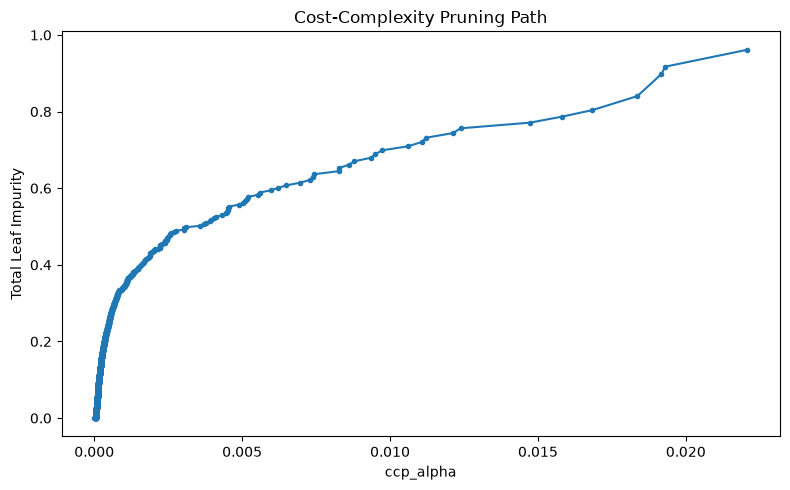

In [32]:
# Plot total leaf impurity across candidate pruning values
plt.figure(figsize=(8, 5))

plt.plot(
    ccp_alphas,
    impurities,
    marker="."
)

plt.xlabel("ccp_alpha")
plt.ylabel("Total Leaf Impurity")
plt.title("Cost-Complexity Pruning Path")
plt.tight_layout()
plt.show()

## 8. Cross-Validated Selection of ccp_alpha

The pruning path produced 1,523 candidate values of `ccp_alpha`. Evaluating
every candidate using 10-fold cross-validation would require more than 15,000
model fits. Therefore, a representative subset of pruning values was first
evaluated using cross-validation. The search was then refined around the
best-performing region of the pruning path.

All tuning was conducted using only the training data. The independent test
set was reserved for final model evaluation.


In [33]:
# Exclude the final alpha representing the maximally pruned tree
candidate_alphas = ccp_alphas[:-1]

# Select 50 representative positions across the pruning path
alpha_indices = np.linspace(
    0,
    len(candidate_alphas) - 1,
    50,
    dtype=int
)

coarse_alphas = np.unique(candidate_alphas[alpha_indices])

print("Candidate alphas used in initial search:", len(coarse_alphas))
print("Smallest candidate:", coarse_alphas.min())
print("Largest candidate:", coarse_alphas.max())

Candidate alphas used in initial search: 43
Smallest candidate: 0.0
Largest candidate: 0.019303032273623733


In [34]:
# Define 10-fold cross-validation
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [35]:
# Define the decision tree used during pruning
pruning_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

# Search the representative ccp_alpha values
coarse_grid = GridSearchCV(
    estimator=pruning_tree,
    param_grid={"ccp_alpha": coarse_alphas},
    cv=cv,
    scoring="accuracy"
)

coarse_grid.fit(X_train, y_train)

print("Best coarse ccp_alpha:", coarse_grid.best_params_["ccp_alpha"])
print("Best coarse CV accuracy:", round(coarse_grid.best_score_, 4))

Best coarse ccp_alpha: 6.25e-05
Best coarse CV accuracy: 0.8748


In [36]:
# Identify where the best coarse alpha occurs in the search grid
best_coarse_alpha = coarse_grid.best_params_["ccp_alpha"]

best_coarse_index = np.where(
    candidate_alphas == best_coarse_alpha
)[0]

print("Best alpha position in original pruning path:", "\n", best_coarse_index)


Best alpha position in original pruning path: 
 [ 70  71  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87
  88  89  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105
 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123
 124 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141
 142 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159
 160 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177
 178 179 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195
 196 197 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213
 214 215 216 217 218 219 220 221 222 223 224 225 226 227 228 229]


In [37]:
# Remove duplicate pruning values
unique_alphas = np.unique(candidate_alphas)

# Locate the best coarse alpha among the unique values
best_coarse_alpha = coarse_grid.best_params_["ccp_alpha"]

best_unique_index = np.argmin(
    np.abs(unique_alphas - best_coarse_alpha)
)

print("Number of unique candidate alphas:", len(unique_alphas))
print("Best coarse alpha:", best_coarse_alpha)
print("Position among unique alphas:", best_unique_index)

# Display nearby unique alpha values
start = max(best_unique_index - 10, 0)
end = min(best_unique_index + 11, len(unique_alphas))

print("\nNearby unique alpha values:")
print(unique_alphas[start:end])

Number of unique candidate alphas: 940
Best coarse alpha: 6.25e-05
Position among unique alphas: 56

Nearby unique alpha values:
[6.17559524e-05 6.17851307e-05 6.18247694e-05 6.20155039e-05
 6.20335821e-05 6.21527778e-05 6.21639785e-05 6.21895695e-05
 6.21999314e-05 6.22106481e-05 6.25000000e-05 6.26876877e-05
 6.66666667e-05 6.89814815e-05 7.50000000e-05 7.50000000e-05
 7.61932926e-05 7.63888889e-05 7.67329389e-05 7.81250000e-05
 8.12500000e-05]


In [38]:
# Select a refined range around the best coarse alpha
start = max(best_unique_index - 15, 0)
end = min(best_unique_index + 16, len(unique_alphas))

refined_alphas = unique_alphas[start:end]

print("Number of refined candidate alphas:", len(refined_alphas))
print("Refined alpha range:")
print(refined_alphas)

Number of refined candidate alphas: 31
Refined alpha range:
[6.13636364e-05 6.13839286e-05 6.14035088e-05 6.15026596e-05
 6.17283951e-05 6.17559524e-05 6.17851307e-05 6.18247694e-05
 6.20155039e-05 6.20335821e-05 6.21527778e-05 6.21639785e-05
 6.21895695e-05 6.21999314e-05 6.22106481e-05 6.25000000e-05
 6.26876877e-05 6.66666667e-05 6.89814815e-05 7.50000000e-05
 7.50000000e-05 7.61932926e-05 7.63888889e-05 7.67329389e-05
 7.81250000e-05 8.12500000e-05 8.12500000e-05 8.13725490e-05
 8.15156812e-05 8.22580645e-05 8.29336531e-05]


In [39]:
# Refine the search around the best-performing pruning region
refined_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={"ccp_alpha": refined_alphas},
    cv=cv,
    scoring="accuracy"
)

refined_grid.fit(X_train, y_train)

best_alpha = refined_grid.best_params_["ccp_alpha"]
best_cv_accuracy = refined_grid.best_score_

print("Best refined ccp_alpha:", best_alpha)
print("Best refined CV accuracy:", round(best_cv_accuracy, 4))

Best refined ccp_alpha: 6.898148148148151e-05
Best refined CV accuracy: 0.8756


In [40]:
# Store the best cross-validated pruned tree
pruned_tree = refined_grid.best_estimator_

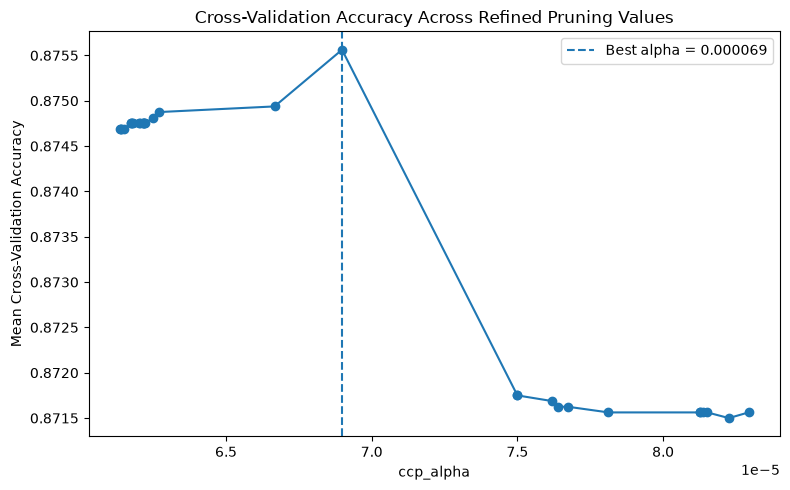

In [41]:
# Review cross-validation performance across the refined alpha values
refined_results = pd.DataFrame(refined_grid.cv_results_)

plt.figure(figsize=(8, 5))

plt.plot(
    refined_results["param_ccp_alpha"].astype(float),
    refined_results["mean_test_score"],
    marker="o"
)

plt.axvline(
    best_alpha,
    linestyle="--",
    label=f"Best alpha = {best_alpha:.6f}"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Cross-Validation Accuracy Across Refined Pruning Values")
plt.legend()
plt.tight_layout()
plt.show()

### Pruning Selection Summary

A two-stage cross-validation search was used to select the cost-complexity
pruning parameter. The refined search identified a `ccp_alpha` value of
approximately 0.000069, with a mean 10-fold cross-validation accuracy of
0.8756. This value was selected using only the training data and was used to
define the final pruned decision tree.
    

In [42]:
# Examine the structure of the selected pruned tree
print("Pruned tree depth:", pruned_tree.get_depth())
print("Pruned number of leaves:", pruned_tree.get_n_leaves())
print("Pruned number of nodes:", pruned_tree.tree_.node_count)

Pruned tree depth: 26
Pruned number of leaves: 1525
Pruned number of nodes: 3049


In [43]:
# Generate predictions from the pruned tree
y_train_pred_pruned = pruned_tree.predict(X_train)
y_test_pred_pruned = pruned_tree.predict(X_test)

In [44]:
# Evaluate the pruned decision tree
pruned_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_pruned
)

pruned_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_pruned
)

pruned_precision = precision_score(
    y_test,
    y_test_pred_pruned,
    average="macro"
)

pruned_recall = recall_score(
    y_test,
    y_test_pred_pruned,
    average="macro"
)

pruned_accuracy_gap = (
    pruned_train_accuracy - pruned_test_accuracy
)

print(f"Training accuracy: {pruned_train_accuracy:.4f}")
print(f"Test accuracy: {pruned_test_accuracy:.4f}")
print(f"Macro precision: {pruned_precision:.4f}")
print(f"Macro recall: {pruned_recall:.4f}")
print(f"Training-test accuracy gap: {pruned_accuracy_gap:.4f}")

Training accuracy: 0.9800
Test accuracy: 0.8705
Macro precision: 0.8729
Macro recall: 0.8715
Training-test accuracy gap: 0.1095


### Pruned Model Performance

The selected cost-complexity parameter reduced the size of the decision tree.
Tree depth decreased from 29 to 26, while the number of leaves decreased from
1,946 to 1,525 and the total number of nodes decreased from 3,891 to 3,049.

The pruned model achieved training accuracy of 0.9800 and test accuracy of
0.8705. Macro-averaged precision was 0.8729 and macro-averaged recall was
0.8715. The training-test accuracy gap decreased from 0.1262 for the
unrestricted tree to 0.1095 after pruning.

Although pruning reduced model complexity and the training-test performance
gap, it did not improve independent test accuracy. Test accuracy decreased
slightly from 0.8738 for the unrestricted model to 0.8705 for the pruned
model. This indicates a tradeoff between model simplicity and predictive
performance in this analysis.
    

In [45]:
# Detailed classification performance for the pruned tree
pruned_report = classification_report(
    y_test,
    y_test_pred_pruned,
    labels=letter_labels
)

print(pruned_report)

              precision    recall  f1-score   support

           A       0.91      0.96      0.94       156
           B       0.70      0.79      0.74       160
           C       0.89      0.89      0.89       147
           D       0.80      0.89      0.84       167
           E       0.88      0.87      0.87       152
           F       0.87      0.85      0.86       156
           G       0.89      0.80      0.84       187
           H       0.80      0.83      0.82       163
           I       0.94      0.90      0.92       147
           J       0.86      0.91      0.89       132
           K       0.80      0.84      0.82       135
           L       0.89      0.92      0.90       160
           M       0.89      0.89      0.89       153
           N       0.93      0.87      0.90       146
           O       0.82      0.83      0.82       145
           P       0.89      0.85      0.87       170
           Q       0.88      0.88      0.88       144
           R       0.86    

In [46]:
# Create confusion matrix for the pruned tree
pruned_cm = confusion_matrix(
    y_test,
    y_test_pred_pruned,
    labels=letter_labels
)

# Identify the most common pruned-model misclassifications
pruned_confusion_df = pd.DataFrame(
    pruned_cm,
    index=letter_labels,
    columns=letter_labels
)

pruned_confusion_pairs = []

for actual in letter_labels:
    for predicted in letter_labels:
        if actual != predicted:
            count = pruned_confusion_df.loc[actual, predicted]

            if count > 0:
                pruned_confusion_pairs.append({
                    "Actual": actual,
                    "Predicted": predicted,
                    "Count": count
                })

top_pruned_confusions = (
    pd.DataFrame(pruned_confusion_pairs)
    .sort_values("Count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_pruned_confusions

,Actual,Predicted,Count
0,X,K,10
1,K,H,9
2,R,B,9
3,R,K,7
4,R,H,7
5,B,S,6
6,P,F,6
7,Z,S,6
8,X,B,6
9,X,D,6


In [47]:
# Summarize pruned-model errors by letter class
pruned_class_errors = pd.DataFrame({
    "Support": pruned_cm.sum(axis=1),
    "Correct": pruned_cm.diagonal()
}, index=letter_labels)

pruned_class_errors["Errors"] = (
    pruned_class_errors["Support"] -
    pruned_class_errors["Correct"]
)

pruned_class_errors["Error Rate"] = (
    pruned_class_errors["Errors"] /
    pruned_class_errors["Support"]
)

pruned_class_errors.sort_values(
    "Error Rate",
    ascending=False
).head(10)

,Support,Correct,Errors,Error Rate
R,153,121,32,0.209150
B,160,127,33,0.206250
G,187,149,38,0.203209
X,169,136,33,0.195266
O,145,120,25,0.172414
H,163,136,27,0.165644
K,135,113,22,0.162963
F,156,132,24,0.153846
P,170,145,25,0.147059
S,151,130,21,0.139073


### Class-Specific Effects of Pruning

The pruned model showed a similar overall pattern of classification errors to
the unrestricted tree, although performance shifted for some individual letter
classes. The error rate for B decreased from 25.0% to approximately 20.6%,
while error rates increased for several classes, including G and X. The most
frequent individual error remained X predicted as K, occurring 10 times.

These results indicate that pruning changed how errors were distributed across
the letter classes but did not produce a uniform improvement in classification
performance.

## 10. Model Interpretation

The final pruned decision tree was examined to identify which image attributes
contributed most strongly to classification. Feature importance values were
calculated from the fitted model, and the upper levels of the tree were
visualized to illustrate how the model recursively divided observations.


In [48]:
# Calculate feature importance values
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": pruned_tree.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance

,Feature,Importance
0,xege,0.140369
1,yege,0.113299
2,y2bar,0.107926
3,xegvy,0.094015
4,x2ybr,0.082382
5,xy2br,0.081413
6,xybar,0.077008
7,x2bar,0.076069
8,yegvx,0.055948
9,ybar,0.055041


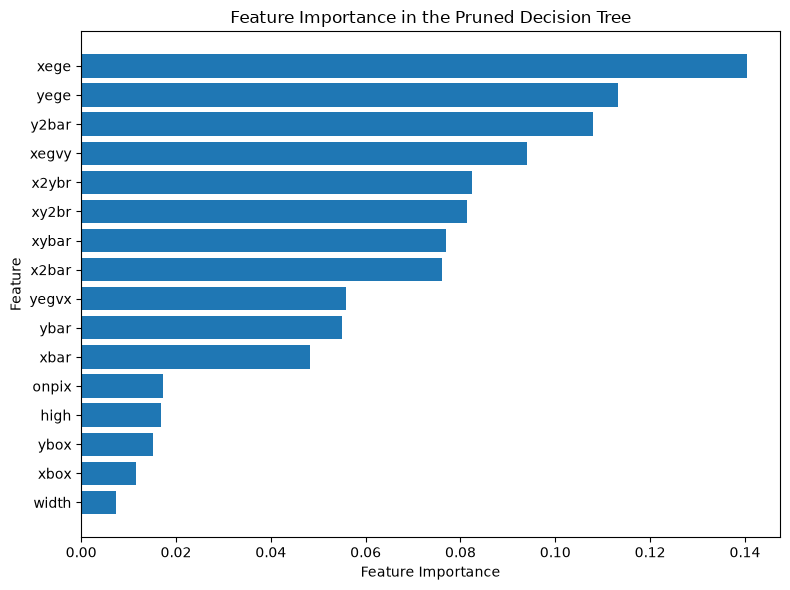

In [49]:
# Plot feature importance values
importance_plot = feature_importance.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(8, 6))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance in the Pruned Decision Tree")
plt.tight_layout()
plt.show()

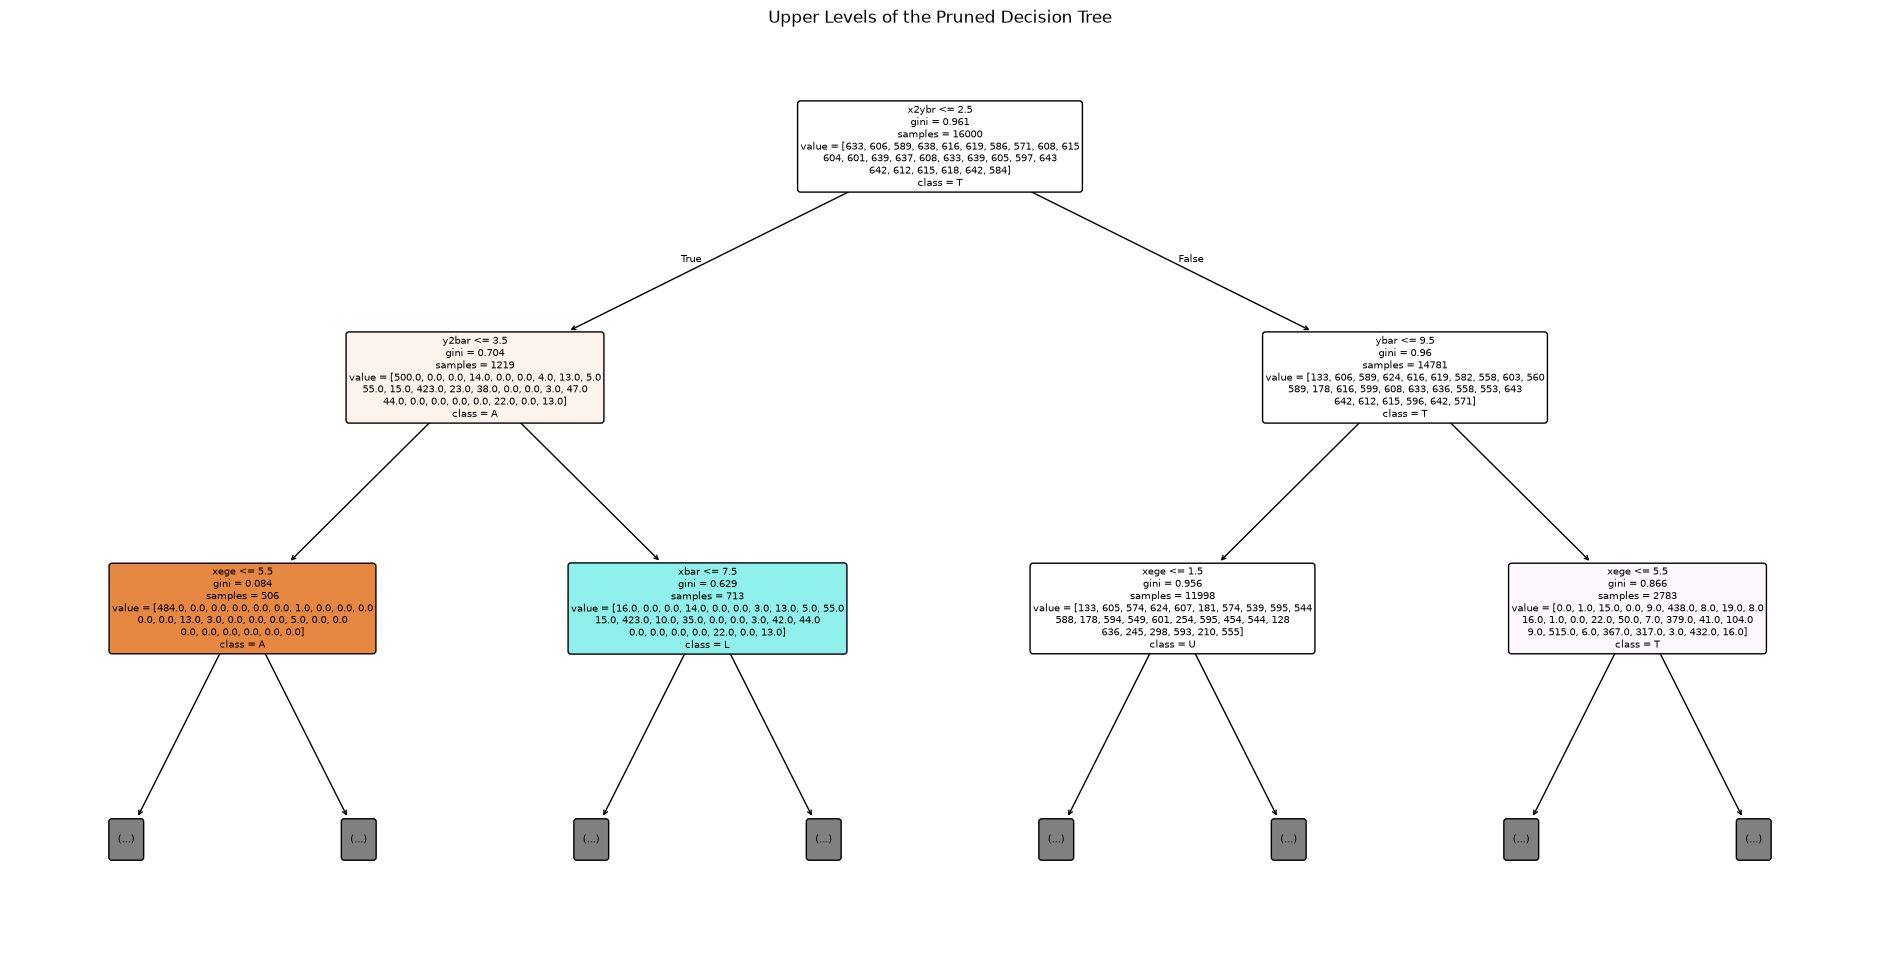

In [50]:
# Visualize only the upper levels of the pruned tree
plt.figure(figsize=(24, 12))

plot_tree(
    pruned_tree,
    feature_names=X_train.columns,
    class_names=pruned_tree.classes_,
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Upper Levels of the Pruned Decision Tree")
plt.show()

In [51]:
from sklearn.tree import export_text

tree_rules = export_text(
    pruned_tree,
    feature_names=list(X_train.columns),
    max_depth=3
)

print(tree_rules)

|--- x2ybr <= 2.50
|   |--- y2bar <= 3.50
|   |   |--- xege <= 5.50
|   |   |   |--- x2bar <= 7.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- x2bar >  7.00
|   |   |   |   |--- class: R
|   |   |--- xege >  5.50
|   |   |   |--- xegvy <= 3.50
|   |   |   |   |--- class: M
|   |   |   |--- xegvy >  3.50
|   |   |   |   |--- class: A
|   |--- y2bar >  3.50
|   |   |--- xbar <= 7.50
|   |   |   |--- yege <= 4.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- yege >  4.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- xbar >  7.50
|   |   |   |--- xege <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- xege >  0.50
|   |   |   |   |--- truncated branch of depth 14
|--- x2ybr >  2.50
|   |--- ybar <= 9.50
|   |   |--- xege <= 1.50
|   |   |   |--- yege <= 4.50
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- yege >  4.50
|   |   |   |   |--- truncated branch of depth 11
|   |   |--- xege >  1.5

### Model Comparison Summary

Cost-complexity pruning reduced the size of the decision tree substantially.
The number of leaves and total nodes decreased by approximately 22%, while
maximum tree depth decreased from 29 to 26. Training accuracy decreased from
1.0000 to 0.9800, and the training-test accuracy gap decreased from 0.1262 to
0.1095.

The reduction in model complexity did not improve independent test performance.
Test accuracy decreased slightly from 0.8738 for the unrestricted model to
0.8705 for the pruned model. Macro precision and recall also changed only
slightly.

Overall, pruning produced a smaller model with a reduced training-test
performance gap, but this simplification involved a small decrease in
predictive performance on the independent test set.
